# 01 · Veri keşfi: IceTracks-DR2

IceCube, Güney Kutbu'ndaki buzun içine yerleştirilmiş 5160 optik sensörden oluşan, 1 km³ hacimli bir nötrino teleskobudur.
Bir muon nötrinosu buzda etkileşince oluşan **muon**, kilometrelerce yol alarak Çerenkov ışığı saçar; bu ışığın izinden
nötrinonun geldiği yön ve enerjisi geri çatılır.

Bu notebook, IceCube'un Mayıs 2026'da yayımladığı **IceTracks-DR2** açık verisini (2008–2022, 14 sezon) tanıtır:
olay sayıları, gökyüzü ve enerji dağılımları, açısal çözünürlük ve dedektörün etkin alanı.

Veri: [Harvard Dataverse doi:10.7910/DVN/MMIIZA](https://doi.org/10.7910/DVN/MMIIZA) · Makale: [arXiv:2605.19040](https://arxiv.org/abs/2605.19040)

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from vcube.data import SEASONS, all_events, load_all
from vcube.irf import EffectiveArea

## Sezonlar
IC40/59/79, inşaat sırasında 40/59/79 dizi ile çalışan kısmi dedektördür; IC86 tam dedektördür (2011'den itibaren).

In [2]:
seasons = load_all()
summary = pd.DataFrame({
    "sezon": [s.name for s in seasons],
    "olay": [len(s.events) for s in seasons],
    "canlı süre [gün]": [round(s.livetime_days, 1) for s in seasons],
    "başlangıç (MJD)": [int(s.events.mjd.min()) for s in seasons],
})
summary["olay / gün"] = (summary["olay"] / summary["canlı süre [gün]"]).round(1)
print(f"Toplam: {summary['olay'].sum():,} olay, {summary['canlı süre [gün]'].sum() / 365.25:.2f} yıl canlı süre")
summary

Toplam: 1,643,355 olay, 13.59 yıl canlı süre


,sezon,olay,canlı süre [gün],başlangıç (MJD),olay / gün
0,IC40,36900,376.4,54562,98.0
1,IC59,107011,353.6,54971,302.6
2,IC79,101956,312.8,55348,325.9
3,IC86_I,118774,339.0,55694,350.4
4,IC86_II,116669,327.1,56043,356.7
5,IC86_III,126535,356.2,56400,355.2
6,IC86_IV,129520,364.9,56757,354.9
7,IC86_V,130389,365.3,57136,356.9
8,IC86_VI,126260,357.2,57528,353.5
9,IC86_VII,147460,410.9,57891,358.9


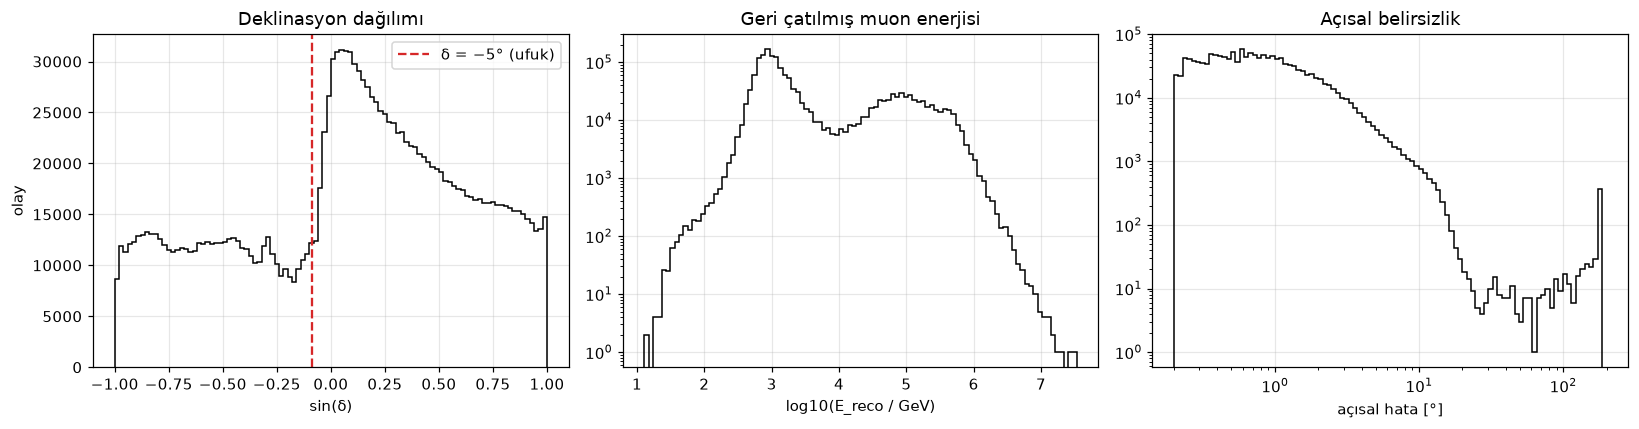

In [3]:
ev = all_events()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(ev.sin_dec, bins=100, histtype="step", color="k")
axes[0].set(xlabel="sin(δ)", ylabel="olay", title="Deklinasyon dağılımı")
axes[0].axvline(np.sin(np.radians(-5)), ls="--", c="C3", label="δ = −5° (ufuk)")
axes[0].legend()

axes[1].hist(ev.logE, bins=100, histtype="step", color="k", log=True)
axes[1].set(xlabel="log10(E_reco / GeV)", title="Geri çatılmış muon enerjisi")

axes[2].hist(ev.ang_err, bins=np.logspace(np.log10(0.2), 2.3, 100), histtype="step", color="k", log=True)
axes[2].set(xscale="log", xlabel="açısal hata [°]", title="Açısal belirsizlik")
fig.tight_layout()
fig.savefig(FIG / "01_dagilimlar.png", bbox_inches="tight")

**Okuma:** Kuzey gökyüzünde (sin δ > 0) Dünya, atmosferik muonları perdeler; buradaki olaylar Dünya'yı geçen nötrinolardır.
Güney gökyüzünde ise atmosferik muon arka planı çok yüksek olduğu için yalnızca yüksek enerjili olaylar seçilir — bu yüzden
güneyde olay sayısı düşer ama ortalama enerji yükselir.

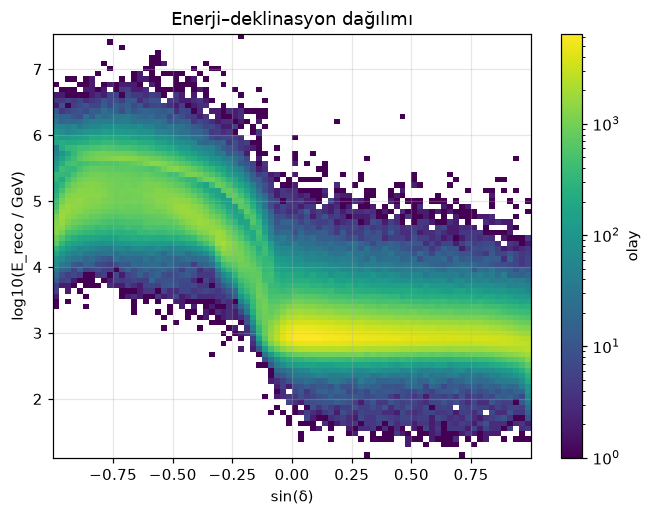

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
h = ax.hist2d(ev.sin_dec, ev.logE, bins=[80, 80], cmap="viridis", norm="log")
plt.colorbar(h[3], label="olay")
ax.set(xlabel="sin(δ)", ylabel="log10(E_reco / GeV)", title="Enerji–deklinasyon dağılımı")
fig.savefig(FIG / "01_enerji_dek.png", bbox_inches="tight")

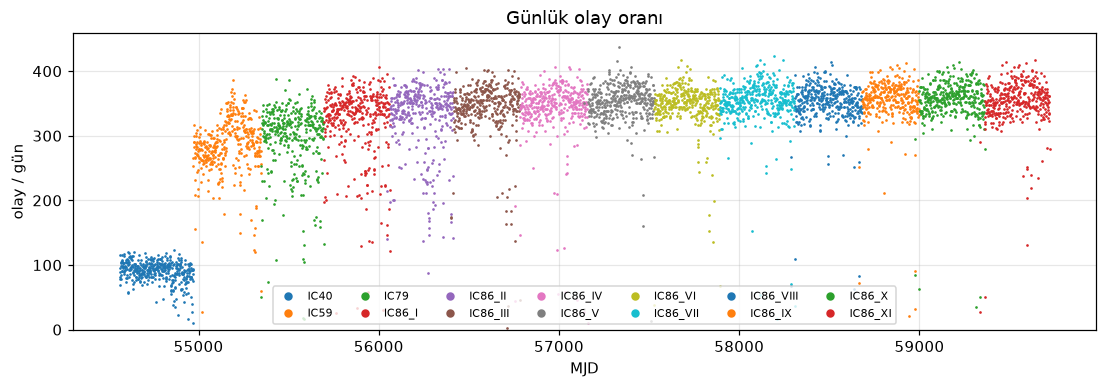

In [5]:
rate = ev.assign(gun=ev.mjd.astype(int)).groupby(["season", "gun"]).size()
fig, ax = plt.subplots(figsize=(12, 3.5))
for s in SEASONS:
    r = rate.loc[s]
    ax.plot(r.index, r.values, ".", ms=1.5, label=s)
ax.set(xlabel="MJD", ylabel="olay / gün", title="Günlük olay oranı", ylim=(0, None))
ax.legend(ncol=7, fontsize=7, markerscale=6)
fig.savefig(FIG / "01_oran.png", bbox_inches="tight")

## Etkin alan
Etkin alan, bir nötrino akısını beklenen olay sayısına çeviren dedektör özelliğidir (≈ dedektörün o nötrinoyu “gördüğü” alan).

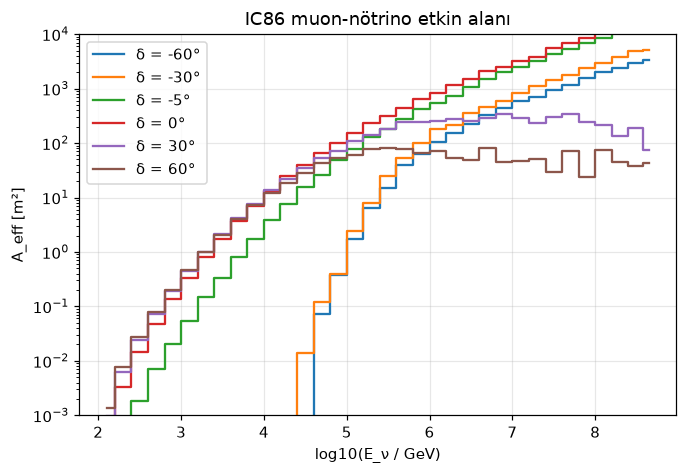

In [6]:
aeff = EffectiveArea.load("IC86")
centres = 0.5 * (aeff.logEnu_edges[1:] + aeff.logEnu_edges[:-1])
fig, ax = plt.subplots(figsize=(7, 4.5))
for dec in (-60, -30, -5, 0, 30, 60):
    ax.step(centres, aeff.aeff_cm2[:, aeff.dec_bin(np.radians(dec))] / 1e4, where="mid", label=f"δ = {dec}°")
ax.set(yscale="log", xlabel="log10(E_ν / GeV)", ylabel="A_eff [m²]", title="IC86 muon-nötrino etkin alanı", ylim=(1e-3, 1e4))
ax.legend()
fig.savefig(FIG / "01_etkin_alan.png", bbox_inches="tight")